# Superstore Retail Sales – Exploratory Data Analysis (EDA)

**Project type:** Data Analytics Internship Project  
**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn, Google Colab / Jupyter

## Project Overview
This notebook performs data quality assessment, cleaning, exploratory analysis and business interpretation of Superstore retail transactions. It examines sales, profitability, discount patterns, customer purchasing behaviour and regional trends.

## Business Objectives
- Prepare transaction data for reliable analysis.
- Profile missing values and check duplicate records.
- Compare sales and profit across product categories and sub-categories.
- Examine discount levels in relation to average profit.
- Identify monthly sales patterns.
- Evaluate regional and customer-segment performance.
- Translate the analysis into actionable business observations.

## Dataset & Preparation Notes
- Original dataset: **10,800 rows and 21 columns**.
- Transaction analysis retains **9,994 rows** with a valid Order Date.
- **806 rows** without a valid Order Date are excluded from transaction-level analysis because they are not valid dated sales transactions for this analysis.
- **11 Postal Code values** are missing and are left missing rather than replaced with invented values.
- The cleaned data contains **zero fully duplicated rows**. Repeated Order IDs are not automatically duplicates because one order can contain multiple product-line records.

## Deliverables in This Notebook
1. Reproducible Python data-cleaning and data-quality checks.
2. Exploratory charts and grouped analysis for categories, discounts, customers, months, regions, segments and sub-categories.
3. At least five annotated business findings, each with an observation, business implication and recommendation.
4. Exported cleaned dataset: `cleaned_superstore.csv`.

## How to Run
1. Open this notebook in Google Colab or Jupyter.
2. Upload/place the original `superstore_sales.csv` in the notebook environment.
3. Run all cells from top to bottom.
4. The notebook creates `cleaned_superstore.csv` in the current working directory.

**Scope note:** Findings describe patterns in this dataset. A relationship between discount and profit is observational and does not, by itself, establish causation.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
print ("All Libraries imported successfully !")


All Libraries imported successfully !


## 1. Import Libraries

## 2. Load and Understand the Dataset

In [2]:
from pathlib import Path

# Locate the source CSV in common Google Colab / Jupyter locations.
possible_paths = [
    Path("/content/superstore_sales.csv"),  # Google Colab upload location
    Path("superstore_sales.csv"),           # Current notebook folder
    Path("/mnt/data/superstore_sales.csv")  # Local working environment
]

file_path = next((path for path in possible_paths if path.exists()), None)
if file_path is None:
    raise FileNotFoundError(
        "superstore_sales.csv was not found. Upload the original CSV to Colab "
        "or place it in the same folder as this notebook."
    )

df = pd.read_csv(file_path)

print("Dataset Loaded Successfully!")
print("Source file:", file_path)
print("Dataset Shape:", df.shape)
display(df.head())


Dataset Loaded Successfully!
Source file: superstore_sales.csv
Dataset Shape: (10800, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2.0,0.00,41.9136
1,2,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3.0,0.00,219.5820
2,3,CA-2017-138688,6/12/2017,6/16/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2.0,0.00,6.8714
3,4,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,0.45,-383.0310
4,5,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.20,2.5164


In [3]:
print("Column Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

Column Names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10800 entries, 0 to 10799
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         10800 non-null  object 
 1   Order ID       10800 non-null  object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    998

,Postal Code,Sales,Quantity,Discount,Profit
count,9983.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,55245.233297,229.858001,3.789574,0.156203,28.656896
std,32038.715955,623.245101,2.225110,0.206452,234.260108
min,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,57103.000000,54.490000,3.000000,0.200000,8.666500
75%,90008.000000,209.940000,5.000000,0.200000,29.364000
max,99301.000000,22638.480000,14.000000,0.800000,8399.976000


In [4]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nStatistical Summary:")
display(df.describe(include='all'))

Dataset Shape: (10800, 21)

Column Names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']

Data Types:
Row ID            object
Order ID          object
Order Date        object
Ship Date         object
Ship Mode         object
Customer ID       object
Customer Name     object
Segment           object
Country           object
City              object
State             object
Postal Code      float64
Region            object
Product ID        object
Category          object
Sub-Category      object
Product Name      object
Sales            float64
Quantity         float64
Discount         float64
Profit           float64
dtype: object

Statistical Summary:


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
count,10800,10800,9994,9994,9994,9994,9994,9994,9994,9994,9994,9983.000000,9994,9994,9994,9994,9994,9994.000000,9994.000000,9994.000000,9994.000000
unique,10001,5015,1236,1334,4,793,793,3,1,531,49,NaN,4,1862,3,17,1850,NaN,NaN,NaN,NaN
top,Yes,CA-2018-100111,9/5/2017,12/16/2016,Standard Class,WB-21850,William Brown,Consumer,United States,New York City,California,NaN,West,OFF-PA-10001970,Office Supplies,Binders,Staple envelope,NaN,NaN,NaN,NaN
freq,800,28,38,35,5968,37,37,5191,9994,915,2001,NaN,3203,19,6026,1523,48,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,55245.233297,NaN,NaN,NaN,NaN,NaN,229.858001,3.789574,0.156203,28.656896
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,32038.715955,NaN,NaN,NaN,NaN,NaN,623.245101,2.225110,0.206452,234.260108
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1040.000000,NaN,NaN,NaN,NaN,NaN,0.444000,1.000000,0.000000,-6599.978000
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,23223.000000,NaN,NaN,NaN,NaN,NaN,17.280000,2.000000,0.000000,1.728750
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,57103.000000,NaN,NaN,NaN,NaN,NaN,54.490000,3.000000,0.200000,8.666500
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,90008.000000,NaN,NaN,NaN,NaN,NaN,209.940000,5.000000,0.200000,29.364000


## 3. Data Quality Assessment

In [5]:
missing = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Missing Percentage': (df.isnull().sum() / len(df)) * 100
})

missing = missing.sort_values(
    by='Missing Values',
    ascending=False
)

display(missing)

,Missing Values,Missing Percentage
Postal Code,817,7.564815
Ship Mode,806,7.462963
Ship Date,806,7.462963
Customer ID,806,7.462963
Order Date,806,7.462963
Product ID,806,7.462963
Category,806,7.462963
Segment,806,7.462963
Customer Name,806,7.462963
Country,806,7.462963


In [6]:
print("Row ID Data Types:")
print(df['Row ID'].value_counts().head(10))

print("\nRows where Row ID is Yes:")
display(df[df['Row ID'] == 'Yes'].head(10))

Row ID Data Types:
Row ID
Yes     800
6663      1
6664      1
6665      1
6666      1
6667      1
6668      1
6669      1
6670      1
6671      1
Name: count, dtype: int64

Rows where Row ID is Yes:


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
10000,Yes,CA-2015-100762,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10001,Yes,CA-2015-100762,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10002,Yes,CA-2015-100762,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10003,Yes,CA-2015-100762,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10004,Yes,CA-2015-100867,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10005,Yes,CA-2015-102652,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10006,Yes,CA-2015-102652,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10007,Yes,CA-2015-102652,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10008,Yes,CA-2015-102652,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10009,Yes,CA-2015-103373,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
print("Completely Empty Rows:",
      df.isnull().all(axis=1).sum())

print("Duplicate Rows:",
      df.duplicated().sum())

Completely Empty Rows: 0
Duplicate Rows: 504


In [8]:
print("Order Date Samples:")
print(df['Order Date'].head(10))

print("\nShip Date Samples:")
print(df['Ship Date'].head(10))

Order Date Samples:
0     11/8/2017
1     11/8/2017
2     6/12/2017
3    10/11/2016
4    10/11/2016
5      6/9/2015
6      6/9/2015
7      6/9/2015
8      6/9/2015
9      6/9/2015
Name: Order Date, dtype: object

Ship Date Samples:
0    11/11/2017
1    11/11/2017
2     6/16/2017
3    10/18/2016
4    10/18/2016
5     6/14/2015
6     6/14/2015
7     6/14/2015
8     6/14/2015
9     6/14/2015
Name: Ship Date, dtype: object


In [9]:
print("Rows with Missing Order Date:")

display(
    df[df['Order Date'].isnull()].head(10)
)

Rows with Missing Order Date:


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
9994,Person,Region,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9995,Anna Andreadi,West,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9996,Chuck Magee,East,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9997,Kelly Williams,Central,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9998,Cassandra Brandow,South,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9999,Returned,Order ID,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10000,Yes,CA-2015-100762,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10001,Yes,CA-2015-100762,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10002,Yes,CA-2015-100762,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10003,Yes,CA-2015-100762,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [10]:
print(
    "Completely Empty Rows:",
    df.isnull().all(axis=1).sum()
)

Completely Empty Rows: 0


In [11]:
print("Rows with missing Order Date:",
      df['Order Date'].isnull().sum())

print("Rows with missing Sales:",
      df['Sales'].isnull().sum())

print("Rows with missing Profit:",
      df['Profit'].isnull().sum())

Rows with missing Order Date: 806
Rows with missing Sales: 806
Rows with missing Profit: 806


In [12]:
display(df.tail(20))

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
10780,Yes,US-2018-118087,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10781,Yes,US-2018-118087,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10782,Yes,US-2018-118087,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10783,Yes,US-2018-118087,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10784,Yes,US-2018-118087,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10785,Yes,US-2018-118087,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10786,Yes,US-2018-123834,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10787,Yes,US-2018-136679,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10788,Yes,US-2018-136679,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10789,Yes,US-2018-147886,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [13]:
print(df['Row ID'].value_counts().head(15))

Row ID
Yes     800
6663      1
6664      1
6665      1
6666      1
6667      1
6668      1
6669      1
6670      1
6671      1
6662      1
6673      1
6674      1
6675      1
6676      1
Name: count, dtype: int64


In [14]:
yes_records = df[df['Row ID'] == 'Yes']

print("Total Yes Records:", len(yes_records))

display(yes_records.head(10))

Total Yes Records: 800


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
10000,Yes,CA-2015-100762,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10001,Yes,CA-2015-100762,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10002,Yes,CA-2015-100762,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10003,Yes,CA-2015-100762,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10004,Yes,CA-2015-100867,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10005,Yes,CA-2015-102652,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10006,Yes,CA-2015-102652,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10007,Yes,CA-2015-102652,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10008,Yes,CA-2015-102652,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10009,Yes,CA-2015-103373,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Data Cleaning and Preparation

Rows without a valid Order Date are excluded from transaction-level analysis. The original `df` remains available, while `cleaned_data` contains the retained sales records.

In [15]:
valid_data = df[df['Order Date'].notna()].copy()

print("Valid Sales Records:", len(valid_data))
print("Extra Records:", len(df) - len(valid_data))

Valid Sales Records: 9994
Extra Records: 806


In [16]:
# Create a separate cleaned dataset
cleaned_data = df[df["Order Date"].notna()].copy()

# Reset index
cleaned_data.reset_index(drop=True, inplace=True)

# Verify the cleaned dataset
print("Original Dataset:", df.shape)
print("Cleaned Dataset:", cleaned_data.shape)

print("Removed Records:", len(df) - len(cleaned_data))

Original Dataset: (10800, 21)
Cleaned Dataset: (9994, 21)
Removed Records: 806


In [17]:
cleaned_data["Order Date"] = pd.to_datetime(
    cleaned_data["Order Date"],
    format="%m/%d/%Y",
    errors="coerce"
)

cleaned_data["Ship Date"] = pd.to_datetime(
    cleaned_data["Ship Date"],
    format="%m/%d/%Y",
    errors="coerce"
)

print(cleaned_data[
    ["Order Date", "Ship Date"]
].dtypes)

Order Date    datetime64[ns]
Ship Date     datetime64[ns]
dtype: object


In [18]:
print("Duplicate Records:",
      cleaned_data.duplicated().sum())

print("Duplicate Order IDs:",
      cleaned_data["Order ID"].duplicated().sum())

Duplicate Records: 0
Duplicate Order IDs: 4985


In [19]:
print(
    "Missing Postal Codes:",
    cleaned_data["Postal Code"].isnull().sum()
)

Missing Postal Codes: 11


In [20]:
cleaned_data.to_csv(
    "cleaned_superstore.csv",
    index=False
)

print("Cleaned Dataset Saved Successfully!")

Cleaned Dataset Saved Successfully!


In [21]:
# Check completely duplicate rows
print("Full Duplicate Rows:", cleaned_data.duplicated().sum())

# Check duplicate Order IDs
print("Duplicate Order IDs:", cleaned_data["Order ID"].duplicated().sum())

# Check missing values after cleaning
print("\nMissing Values:")
print(cleaned_data.isnull().sum())

Full Duplicate Rows: 0
Duplicate Order IDs: 4985

Missing Values:
Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country           0
City              0
State             0
Postal Code      11
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
Quantity          0
Discount          0
Profit            0
dtype: int64


In [22]:
# Convert dates into datetime format
cleaned_data["Order Date"] = pd.to_datetime(
    cleaned_data["Order Date"], errors="coerce"
)

cleaned_data["Ship Date"] = pd.to_datetime(
    cleaned_data["Ship Date"], errors="coerce"
)

# Extract Year and Month
cleaned_data["Year"] = cleaned_data["Order Date"].dt.year
cleaned_data["Month"] = cleaned_data["Order Date"].dt.month

# Create Year-Month column
cleaned_data["Year-Month"] = cleaned_data["Order Date"].dt.to_period("M")

print(cleaned_data[["Order Date", "Year", "Month", "Year-Month"]].head())

  Order Date  Year  Month Year-Month
0 2017-11-08  2017     11    2017-11
1 2017-11-08  2017     11    2017-11
2 2017-06-12  2017      6    2017-06
3 2016-10-11  2016     10    2016-10
4 2016-10-11  2016     10    2016-10


In [23]:
print("Final Dataset Shape:", cleaned_data.shape)
print("\nData Types:")
print(cleaned_data.dtypes)

Final Dataset Shape: (9994, 24)

Data Types:
Row ID                   object
Order ID                 object
Order Date       datetime64[ns]
Ship Date        datetime64[ns]
Ship Mode                object
Customer ID              object
Customer Name            object
Segment                  object
Country                  object
City                     object
State                    object
Postal Code             float64
Region                   object
Product ID               object
Category                 object
Sub-Category             object
Product Name             object
Sales                   float64
Quantity                float64
Discount                float64
Profit                  float64
Year                      int32
Month                     int32
Year-Month            period[M]
dtype: object


### Data-cleaning decisions and quality notes

- Rows with a missing `Order Date` are excluded from the transaction analysis; this removes 806 non-transaction/appended rows from the original 10,800-row file.
- `Order Date` and `Ship Date` are converted to datetime values so date-based analysis can be performed reliably.
- Full-row duplicates are checked separately from repeated `Order ID` values. Repeated order IDs are expected when an order contains multiple product lines, so they are not removed as duplicates.
- The 11 missing `Postal Code` values are retained. Postal Code is not required for the analyses in this notebook, and no unsupported values are imputed.
- `Year`, `Month` and `Year-Month` are derived from `Order Date` for trend analysis.

These are documented treatment decisions; the notebook does not claim that every missing value was filled.


## 5. Category-wise Sales, Profit and Profit Margin

In [24]:
# Category-wise Sales and Profit
category_analysis = cleaned_data.groupby("Category").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum")
).reset_index()

# Sort by Sales
category_analysis = category_analysis.sort_values(
    by="Total_Sales", ascending=False
)

print(category_analysis)

          Category  Total_Sales  Total_Profit  Total_Quantity
2       Technology  836154.0330   145454.9481          6939.0
0        Furniture  741999.7953    18451.2728          8028.0
1  Office Supplies  719047.0320   122490.8008         22906.0


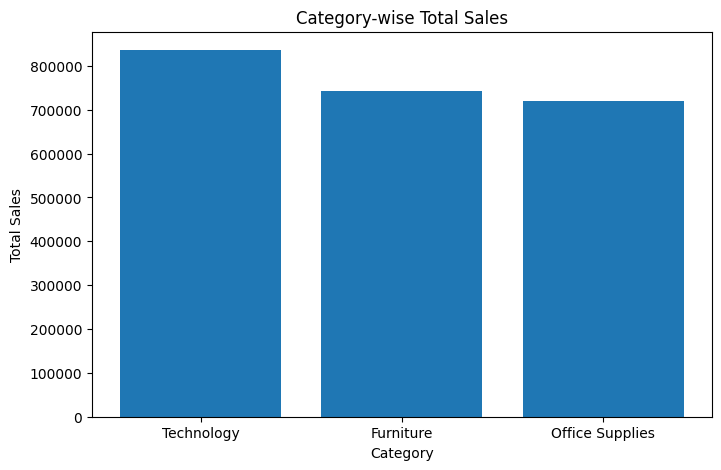

In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    category_analysis["Category"],
    category_analysis["Total_Sales"]
)

plt.title("Category-wise Total Sales")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.show()

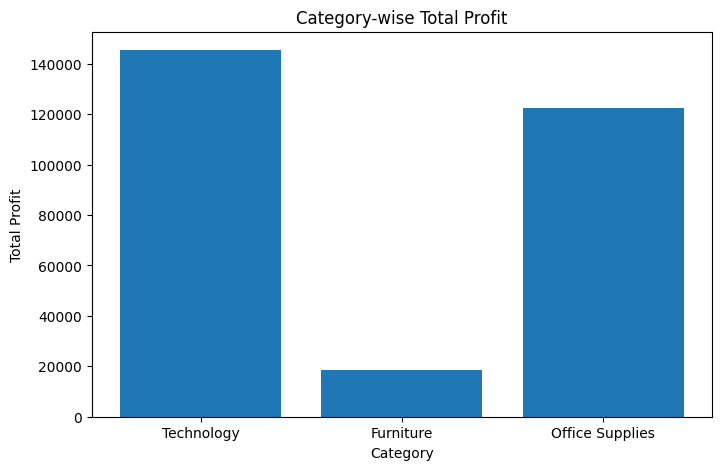

In [26]:
plt.figure(figsize=(8, 5))

plt.bar(
    category_analysis["Category"],
    category_analysis["Total_Profit"]
)

plt.title("Category-wise Total Profit")
plt.xlabel("Category")
plt.ylabel("Total Profit")
plt.show()

In [27]:
category_analysis["Profit_Margin_%"] = (
    category_analysis["Total_Profit"] /
    category_analysis["Total_Sales"]
) * 100

print(category_analysis.round(2))

          Category  Total_Sales  Total_Profit  Total_Quantity  Profit_Margin_%
2       Technology    836154.03     145454.95          6939.0            17.40
0        Furniture    741999.80      18451.27          8028.0             2.49
1  Office Supplies    719047.03     122490.80         22906.0            17.04


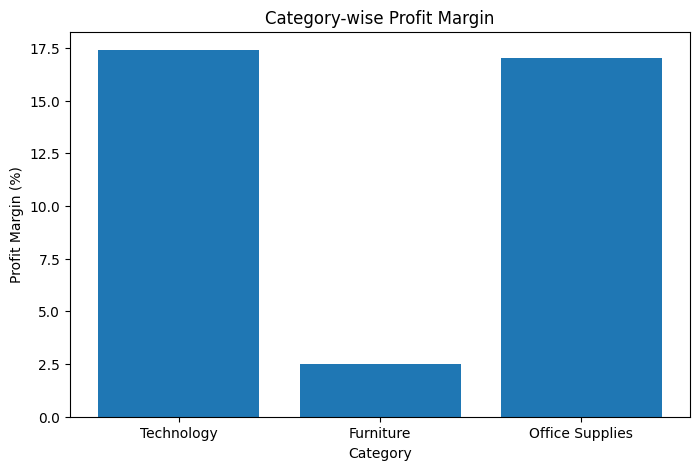

In [28]:
plt.figure(figsize=(8, 5))

plt.bar(
    category_analysis["Category"],
    category_analysis["Profit_Margin_%"]
)

plt.title("Category-wise Profit Margin")
plt.xlabel("Category")
plt.ylabel("Profit Margin (%)")
plt.show()

## 6. Discount Analysis

This section compares discount levels with average profit. The relationship is descriptive and does not by itself prove causation.

In [29]:
discount_analysis = cleaned_data.groupby(
    ["Category", "Discount"]
).agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order ID", "nunique")
).reset_index()

print(discount_analysis.round(2).to_string(index=False))

       Category  Discount  Total_Sales  Total_Profit  Total_Orders
      Furniture      0.00    256025.27      58133.08           739
      Furniture      0.10     46634.25       7111.01            71
      Furniture      0.15     27558.52       1418.99            51
      Furniture      0.20    216631.02       6265.95           539
      Furniture      0.30     99470.35     -10695.32           207
      Furniture      0.32     14493.46      -2391.14            27
      Furniture      0.40     45614.41     -16187.40            72
      Furniture      0.45      5484.97      -2493.11            10
      Furniture      0.50     20983.47     -12871.20            53
      Furniture      0.60      6644.70      -5944.66           127
      Furniture      0.70      2459.38      -3894.94            15
Office Supplies      0.00    442150.00     130506.11          2020
Office Supplies      0.10      4324.15       1086.08            16
Office Supplies      0.20    233049.74      38038.75          

    Discount  Average_Profit  Total_Transactions
0       0.00           66.90                4798
1       0.10           96.06                  94
2       0.15           27.29                  52
3       0.20           24.70                3657
4       0.30          -45.68                 227
5       0.32          -88.56                  27
6       0.40         -111.93                 206
7       0.45         -226.65                  11
8       0.50         -310.70                  66
9       0.60          -43.08                 138
10      0.70          -95.87                 418
11      0.80         -101.80                 300


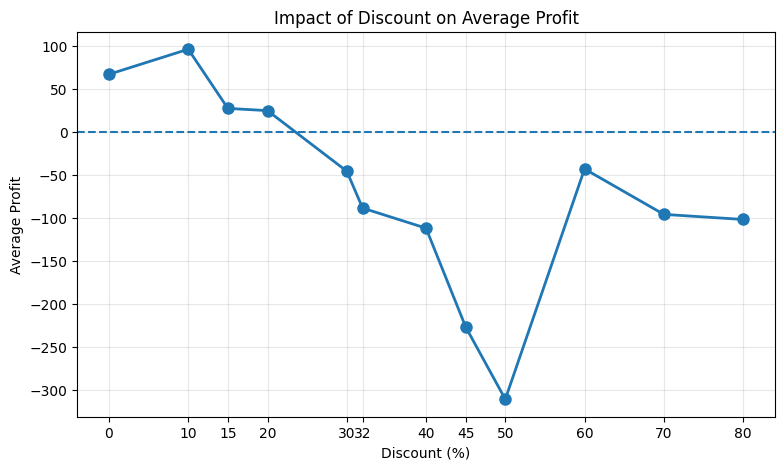

In [30]:
# Calculate average profit for each discount level
discount_profit = cleaned_data.groupby("Discount").agg(
    Average_Profit=("Profit", "mean"),
    Total_Transactions=("Profit", "count")
).reset_index()

print(discount_profit.round(2))

# Create clear line chart
plt.figure(figsize=(9, 5))

plt.plot(
    discount_profit["Discount"] * 100,
    discount_profit["Average_Profit"],
    marker="o",
    linewidth=2,
    markersize=8
)

plt.axhline(y=0, linestyle="--")

plt.title("Impact of Discount on Average Profit")
plt.xlabel("Discount (%)")
plt.ylabel("Average Profit")
plt.xticks(discount_profit["Discount"] * 100)
plt.grid(True, alpha=0.3)

plt.show()

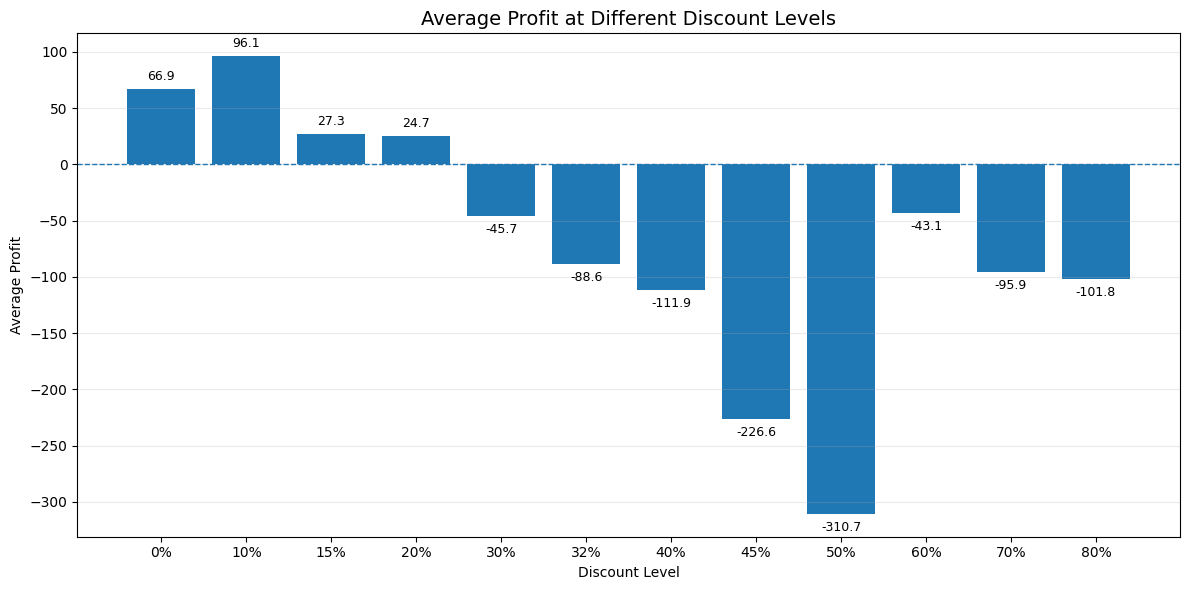

In [31]:
import matplotlib.pyplot as plt

# Convert discount values into readable percentage labels
discount_profit = discount_profit.sort_values("Discount").copy()

discount_profit["Discount_Label"] = (
    (discount_profit["Discount"] * 100).round(0).astype(int).astype(str) + "%"
)

plt.figure(figsize=(12, 6))

bars = plt.bar(
    discount_profit["Discount_Label"],
    discount_profit["Average_Profit"]
)

# Zero profit reference line
plt.axhline(0, linestyle="--", linewidth=1)

# Add profit values on bars
for bar in bars:
    value = bar.get_height()
    position = value + 8 if value >= 0 else value - 15

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        position,
        f"{value:.1f}",
        ha="center",
        fontsize=9
    )

plt.title("Average Profit at Different Discount Levels", fontsize=14)
plt.xlabel("Discount Level")
plt.ylabel("Average Profit")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## 7. Customer Purchase Analysis

In [32]:
customer_analysis = cleaned_data.groupby(
    ["Customer ID", "Customer Name"]
).agg(
    Total_Orders=("Order ID", "nunique"),
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum")
).reset_index()

# Top 10 customers by sales
top_customers = customer_analysis.sort_values(
    by="Total_Sales", ascending=False
).head(10)

print(top_customers.round(2).to_string(index=False))

Customer ID      Customer Name  Total_Orders  Total_Sales  Total_Profit  Total_Quantity
   SM-20320        Sean Miller             5     25043.05      -1980.74            50.0
   TC-20980       Tamara Chand             5     19052.22       8981.32            42.0
   RB-19360       Raymond Buch             6     15117.34       6976.10            71.0
   TA-21385       Tom Ashbrook             4     14595.62       4703.79            36.0
   AB-10105      Adrian Barton            10     14473.57       5444.81            73.0
   KL-16645       Ken Lonsdale            12     14175.23        806.86           113.0
   SC-20095       Sanjit Chand             9     14142.33       5757.41            87.0
   HL-15040       Hunter Lopez             6     12873.30       5622.43            50.0
   SE-20110       Sanjit Engle            11     12209.44       2650.68            78.0
   CC-12370 Christopher Conant             5     12129.07       2177.05            34.0


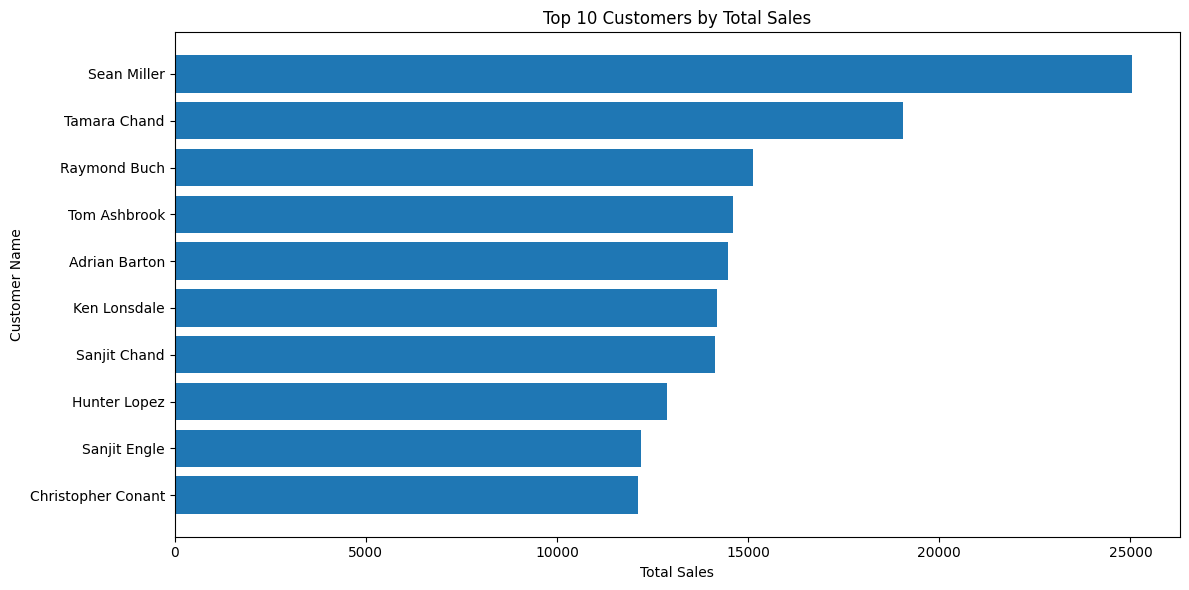

In [33]:
plt.figure(figsize=(12, 6))

plt.barh(
    top_customers["Customer Name"],
    top_customers["Total_Sales"]
)

plt.title("Top 10 Customers by Total Sales")
plt.xlabel("Total Sales")
plt.ylabel("Customer Name")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

## 8. Monthly Sales Trend Analysis

In [34]:
monthly_sales = cleaned_data.groupby("Year-Month").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order ID", "nunique")
).reset_index()

monthly_sales["Year-Month"] = (
    monthly_sales["Year-Month"].astype(str)
)

print(monthly_sales.to_string(index=False))

Year-Month  Total_Sales  Total_Profit  Total_Orders
   2015-01   14236.8950     2450.1907            32
   2015-02    4519.8920      862.3084            28
   2015-03   55691.0090      498.7299            71
   2015-04   28295.3450     3488.8352            66
   2015-05   23648.2870     2738.7096            69
   2015-06   34595.1276     4976.5244            66
   2015-07   33946.3930     -841.4826            65
   2015-08   27909.4685     5318.1050            72
   2015-09   81777.3508     8328.0994           130
   2015-10   31453.3930     3448.2573            78
   2015-11   78628.7167     9292.1269           151
   2015-12   69545.6205     8983.5699           141
   2016-01   18174.0756    -3281.0070            29
   2016-02   11951.4110     2813.8508            36
   2016-03   38726.2520     9732.0978            79
   2016-04   34195.2085     4187.4962            72
   2016-05   30131.6865     4667.8690            74
   2016-06   24797.2920     3335.5572            68
   2016-07  

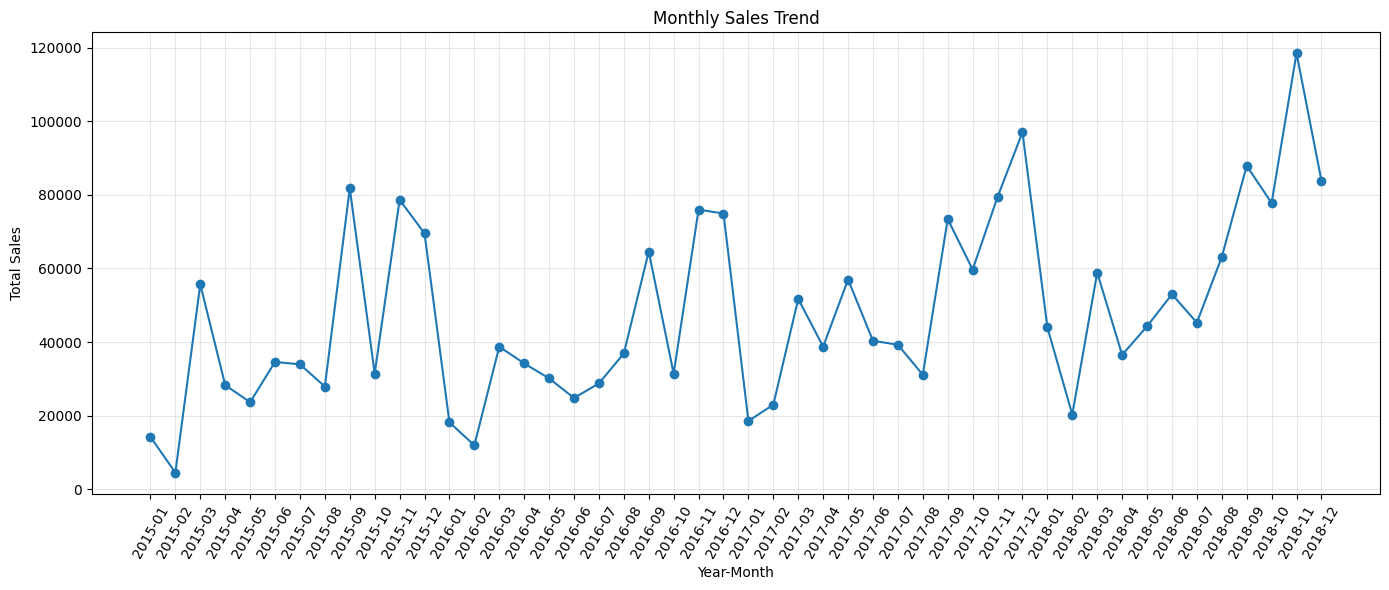

In [35]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales["Year-Month"],
    monthly_sales["Total_Sales"],
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Year-Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=60)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 9. Region-wise Sales and Profit Analysis

In [36]:
region_analysis = cleaned_data.groupby("Region").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order ID", "nunique"),
    Total_Quantity=("Quantity", "sum")
).reset_index()

region_analysis = region_analysis.sort_values(
    by="Total_Sales", ascending=False
)

print(region_analysis.round(2).to_string(index=False))

 Region  Total_Sales  Total_Profit  Total_Orders  Total_Quantity
   West    725457.82     108418.45          1611         12266.0
   East    678781.24      91522.78          1401         10618.0
Central    501239.89      39706.36          1175          8780.0
  South    391721.90      46749.43           822          6209.0


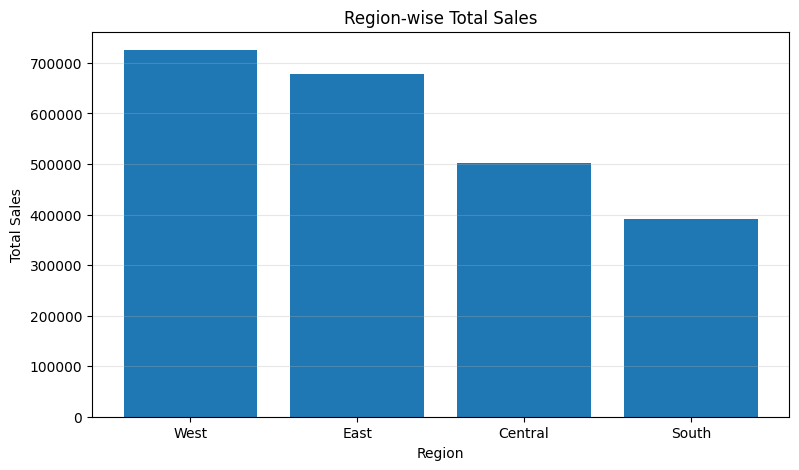

In [37]:
plt.figure(figsize=(9, 5))

plt.bar(
    region_analysis["Region"],
    region_analysis["Total_Sales"]
)

plt.title("Region-wise Total Sales")
plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.grid(axis="y", alpha=0.3)
plt.show()

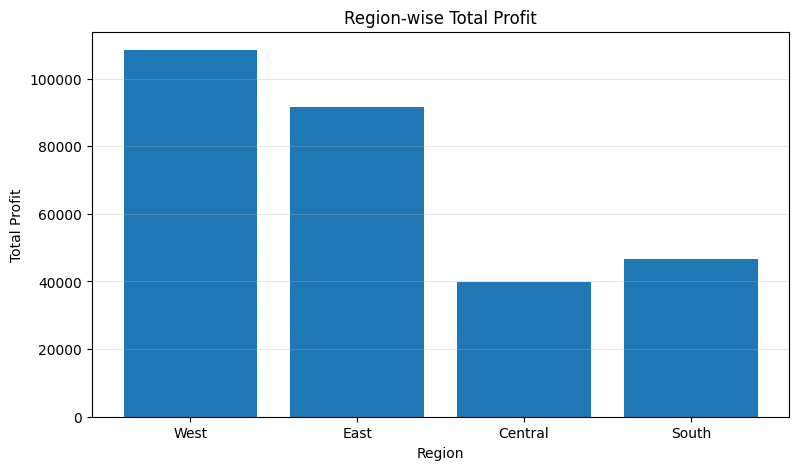

In [38]:
plt.figure(figsize=(9, 5))

plt.bar(
    region_analysis["Region"],
    region_analysis["Total_Profit"]
)

plt.title("Region-wise Total Profit")
plt.xlabel("Region")
plt.ylabel("Total Profit")
plt.grid(axis="y", alpha=0.3)
plt.show()

In [39]:
region_analysis["Profit_Margin_%"] = (
    region_analysis["Total_Profit"] /
    region_analysis["Total_Sales"]
) * 100

print(region_analysis.round(2).to_string(index=False))

 Region  Total_Sales  Total_Profit  Total_Orders  Total_Quantity  Profit_Margin_%
   West    725457.82     108418.45          1611         12266.0            14.94
   East    678781.24      91522.78          1401         10618.0            13.48
Central    501239.89      39706.36          1175          8780.0             7.92
  South    391721.90      46749.43           822          6209.0            11.93


## 10. Customer Segment Analysis

In [40]:
segment_analysis = cleaned_data.groupby("Segment").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order ID", "nunique"),
    Total_Quantity=("Quantity", "sum")
).reset_index()

segment_analysis["Profit_Margin_%"] = (
    segment_analysis["Total_Profit"] /
    segment_analysis["Total_Sales"]
) * 100

print(segment_analysis.round(2).to_string(index=False))

    Segment  Total_Sales  Total_Profit  Total_Orders  Total_Quantity  Profit_Margin_%
   Consumer   1161401.34     134119.21          2586         19521.0            11.55
  Corporate    706146.37      91979.13          1514         11608.0            13.03
Home Office    429653.15      60298.68           909          6744.0            14.03


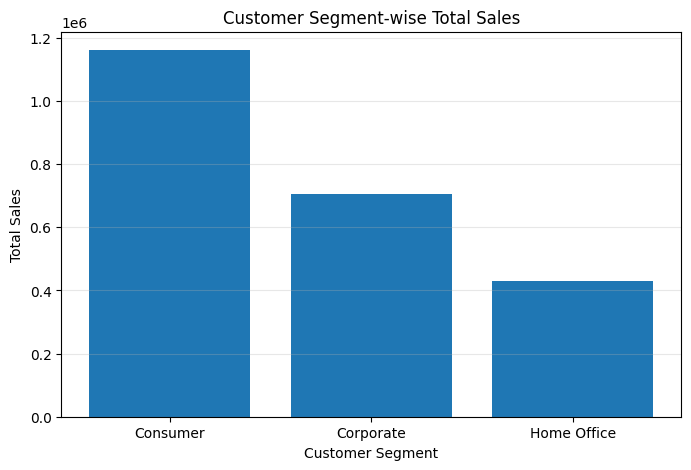

In [41]:
plt.figure(figsize=(8, 5))

plt.bar(
    segment_analysis["Segment"],
    segment_analysis["Total_Sales"]
)

plt.title("Customer Segment-wise Total Sales")
plt.xlabel("Customer Segment")
plt.ylabel("Total Sales")
plt.grid(axis="y", alpha=0.3)
plt.show()

## 11. Product Sub-Category Profitability

In [42]:
subcategory_analysis = cleaned_data.groupby("Sub-Category").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum")
).reset_index()

subcategory_analysis = subcategory_analysis.sort_values(
    by="Total_Profit", ascending=False
)

print(subcategory_analysis.round(2).to_string(index=False))

Sub-Category  Total_Sales  Total_Profit  Total_Quantity
     Copiers    149528.03      55617.82           234.0
      Phones    330007.05      44515.73          3289.0
 Accessories    167380.32      41936.64          2976.0
       Paper     78479.21      34053.57          5178.0
     Binders    203412.73      30221.76          5974.0
      Chairs    328449.10      26590.17          2356.0
     Storage    223843.61      21278.83          3158.0
  Appliances    107532.16      18138.01          1729.0
 Furnishings     91705.16      13059.14          3563.0
   Envelopes     16476.40       6964.18           906.0
         Art     27118.79       6527.79          3000.0
      Labels     12486.31       5546.25          1400.0
    Machines    189238.63       3384.76           440.0
   Fasteners      3024.28        949.52           914.0
    Supplies     46673.54      -1189.10           647.0
   Bookcases    114880.00      -3472.56           868.0
      Tables    206965.53     -17725.48         

In [43]:
# Calculate sub-category performance
subcategory_analysis = cleaned_data.groupby("Sub-Category").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum")
).reset_index()

# Identify top and bottom performers
top_profit = subcategory_analysis.loc[
    subcategory_analysis["Total_Profit"].idxmax()
]

lowest_profit = subcategory_analysis.loc[
    subcategory_analysis["Total_Profit"].idxmin()
]

print("Most Profitable Sub-Category:", top_profit["Sub-Category"])
print("Highest Profit:", round(top_profit["Total_Profit"], 2))

print("\nLowest Profit Sub-Category:", lowest_profit["Sub-Category"])
print("Lowest Profit:", round(lowest_profit["Total_Profit"], 2))

Most Profitable Sub-Category: Copiers
Highest Profit: 55617.82

Lowest Profit Sub-Category: Tables
Lowest Profit: -17725.48


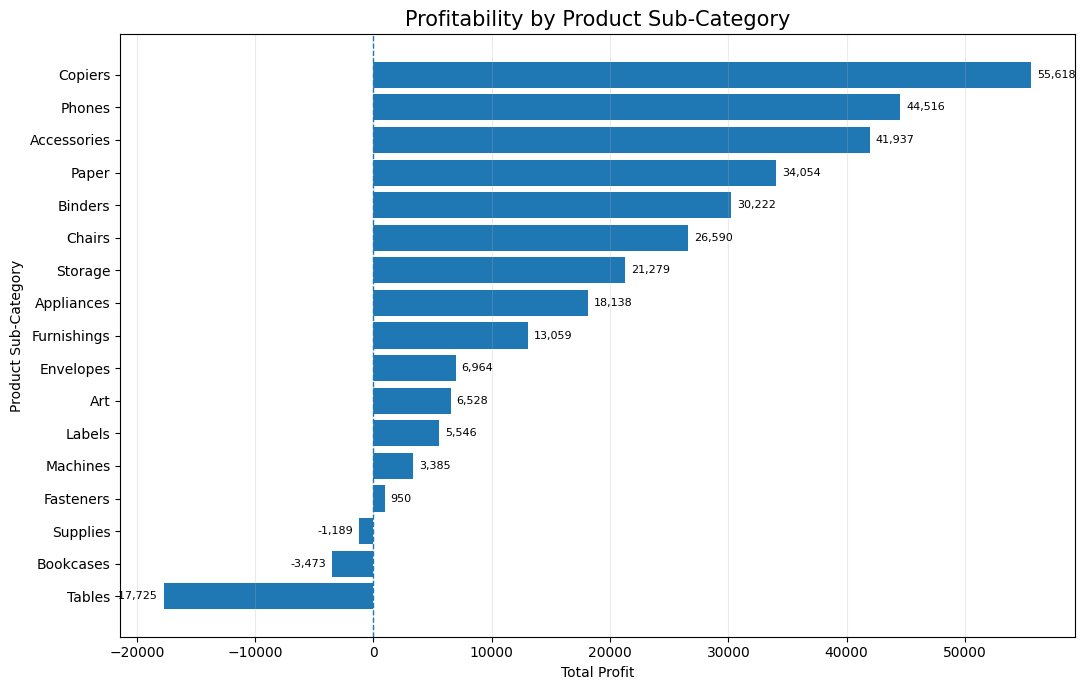

In [44]:
import matplotlib.pyplot as plt

chart_data = subcategory_analysis.sort_values(
    "Total_Profit", ascending=True
)

plt.figure(figsize=(11, 7))

bars = plt.barh(
    chart_data["Sub-Category"],
    chart_data["Total_Profit"]
)

plt.axvline(0, linestyle="--", linewidth=1)

plt.title("Profitability by Product Sub-Category", fontsize=15)
plt.xlabel("Total Profit")
plt.ylabel("Product Sub-Category")
plt.grid(axis="x", alpha=0.25)

for bar in bars:
    value = bar.get_width()
    plt.text(
        value + 500 if value >= 0 else value - 500,
        bar.get_y() + bar.get_height()/2,
        f"{value:,.0f}",
        va="center",
        ha="left" if value >= 0 else "right",
        fontsize=8
    )

plt.tight_layout()
plt.show()

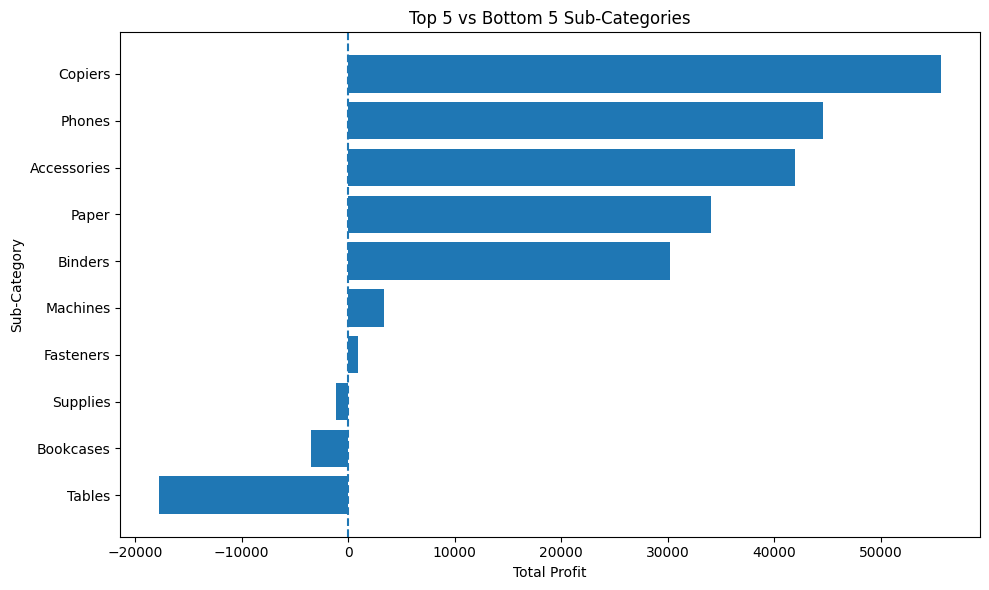

In [45]:
top_5 = subcategory_analysis.nlargest(5, "Total_Profit")

bottom_5 = subcategory_analysis.nsmallest(5, "Total_Profit")

comparison = pd.concat([top_5, bottom_5])

comparison = comparison.sort_values("Total_Profit")

plt.figure(figsize=(10, 6))

plt.barh(
    comparison["Sub-Category"],
    comparison["Total_Profit"]
)

plt.axvline(0, linestyle="--")

plt.title("Top 5 vs Bottom 5 Sub-Categories")
plt.xlabel("Total Profit")
plt.ylabel("Sub-Category")

plt.tight_layout()
plt.show()

## 12. Key Business Insights and Recommendations

## 13. Five Annotated Business Findings

The findings below summarize the analysis shown in the preceding tables and charts. Each finding separates the data observation from its business implication and suggested action.

### Finding 1 – Category Performance
**Observation:** Technology generated the highest category sales (approximately 836,154). Furniture had a much lower profit margin (approximately 2.49%) than Technology (17.40%) and Office Supplies (17.04%).

**Business implication:** Furniture contributes substantial revenue, but its comparatively low margin means that sales volume alone does not reflect its profitability.

**Recommendation:** Review Furniture product costs, pricing and discount practices. Investigate the specific products and transactions responsible for the low margin before changing prices.

### Finding 2 – Discount and Profit Relationship
**Observation:** Average profit varied across discount levels. The 50% discount group recorded the lowest average profit (approximately -310.70 per transaction in this dataset).

**Business implication:** Higher discount levels are associated with weaker average profit in several discount bands. This is an observed relationship, not proof that discounts alone caused the losses; product mix and transaction characteristics may also matter.

**Recommendation:** Review high-discount transactions by category and sub-category, and evaluate discount rules using both sales and profit rather than sales alone.

### Finding 3 – Monthly Sales Trend
**Observation:** Monthly sales fluctuated during 2015–2018. November 2018 recorded the highest monthly sales (approximately 118,448), while February 2015 recorded the lowest (approximately 4,520).

**Business implication:** Sales volumes vary considerably by month, which is relevant to stock, staffing and campaign planning.

**Recommendation:** Compare the same months across multiple years and investigate major peaks and dips before treating them as recurring seasonal patterns.

### Finding 4 – Regional Performance
**Observation:** West recorded the highest regional sales (approximately 725,458), total profit (approximately 108,418) and profit margin (14.94%). Central had the lowest regional profit margin (7.92%).

**Business implication:** Regional performance differs not only in sales volume but also in the profit earned from those sales.

**Recommendation:** Examine product mix, discounting and operating factors in Central, and study the West region's stronger performance for practices that may be transferable.

### Finding 5 – Customer Segment Performance
**Observation:** Consumer customers generated the highest sales (approximately 1,161,401) and total profit (approximately 134,119). Home Office had the highest segment profit margin (14.03%).

**Business implication:** The largest segment by revenue is not the segment with the highest profit margin; segment size and profitability provide different perspectives.

**Recommendation:** Continue monitoring Consumer sales while exploring suitable ways to grow the Home Office segment without weakening its margin.

### Additional Finding – Sub-Category Profitability
**Observation:** Copiers generated the highest sub-category profit (approximately 55,618), while Tables recorded the largest loss (approximately -17,725). Bookcases and Supplies also recorded negative total profit.

**Business implication:** Profitability varies substantially within product categories, so category-level totals can hide individual product-line issues.

**Recommendation:** Investigate loss-making sub-categories at product and transaction level, including discount, cost and sales mix, before deciding on corrective action.

## Overall Business Recommendations
- Review Furniture pricing, product costs and discount practices.
- Investigate high-discount transactions and loss-making sub-categories.
- Study the West region's performance and identify improvement opportunities in Central.
- Balance Consumer sales growth with the strong margin of Home Office.
- Use multi-year monthly comparisons to support inventory and sales planning.

**Interpretation caution:** These findings are descriptive. They identify patterns in the available data and should be validated with further business context before operational decisions are made.


## 14. Export the Cleaned Dataset

In [46]:
cleaned_data.to_csv("cleaned_superstore.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


## 15. Conclusion

This notebook delivers the data-cleaning workflow, data-quality checks, exploratory charts and five annotated business findings required for the EDA task. The exploratory analysis highlights differences in sales contribution and profitability across categories, regions, customer segments, discount levels, and product sub-categories. The results can help guide further investigation into low-margin and loss-making areas.